# 01 – Esplorazione dei Dati, Preprocessing e Split per Traiettoria

**Ruolo nella pipeline incrementale:** questo notebook **non fa parte dei 4 modelli ($M_1$–$M_4$)**, ma costituisce la **fondazione condivisa** del progetto. Carica il dataset grezzo delle simulazioni quantistiche (catena di Rydberg PXP a 10 qubit), ne verifica l'integrità fisica (bound $[-1, 1]$ e positività quantistica), crea la cache binaria `.npy` e congela lo **split Train / Validation / Test per traiettoria**. Tutti i modelli successivi partiranno da questi stessi artefatti per garantire confronti equi nella Tabella 1 finale.

### Le 55 Osservabili del Dataset
A ogni istante $t \in [0, 20]$ ($\Delta t = 0.02$, $1001$ step), lo stato della catena di 10 qubit è descritto da 55 valori di aspettazione di Pauli in $[-1, 1]$:
* **10 Magnetizzazioni locali ($m_i = \langle \sigma_z^{(i)} \rangle$)**: orientazione media di ciascun atomo.
* **45 Correlazioni a due corpi ($c_{ij} = \langle \sigma_z^{(i)}\sigma_z^{(j)} \rangle$, $i < j$)**: interazione spaziale tra tutte le coppie di qubit.

### Output condivisi generati
* `data/cache/trajectories.npy`: tensore 3D `(400, 1001, 55)` in `float32` (~88 MB, caricamento $< 0.1\text{ s}$).
* `results/split_indices.npz`: indici congelati delle 280 traiettorie di Train, 60 di Validation e 60 di Test.

## 0. Setup dell'Ambiente e Gestione Multi-Utente

Rilevamento automatico dell'ambiente (Google Colab con Drive vs PC locale) e configurazione Git tramite i Secret di Colab (🔑):
* **`GIT_E_TOKEN`** $\to$ **Ernesto** (branch `dev-ernesto`)
* **`GIT_R_TOKEN`** $\to$ **Riccardo** (branch `dev-riccardo`)

Fissiamo inoltre il seme globale `SEED = 42` per la riproducibilità numerica.

In [1]:
# =============================================================================
# 0. Setup Ambiente, Rilevamento Autore da Segreto Colab e Sincronizzazione Git
# =============================================================================
import os
import sys
import time
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

AUTHOR = None
CURRENT_BRANCH = None
GIT_TOKEN = None
AUTHOR_NAME = None
AUTHOR_EMAIL = None

if IN_COLAB:
    from google.colab import drive, userdata
    drive.mount("/content/drive")

    DRIVE_REPO = Path("/content/drive/MyDrive/DL-Quantum")
    LOCAL_REPO = Path("/content/DL-Quantum")

    if (DRIVE_REPO / "src" / "seeding.py").exists():
        REPO_PATH = DRIVE_REPO
    elif (LOCAL_REPO / "src" / "seeding.py").exists():
        REPO_PATH = LOCAL_REPO
    elif DRIVE_REPO.exists():
        !git -C /content/drive/MyDrive/DL-Quantum fetch origin
        REPO_PATH = DRIVE_REPO
    else:
        print("Clonazione automatica del repository su Google Drive...")
        !git clone https://github.com/Riccardo-27/DL-Quantum.git /content/drive/MyDrive/DL-Quantum
        REPO_PATH = DRIVE_REPO

    # 1. Rilevamento automatico dell'Autore dai Segreti di Colab (icona 🔑)
    # - Ernesto: imposta GIT_E_TOKEN nei propri Secret -> dev-ernesto
    # - Riccardo: imposta GIT_R_TOKEN nei propri Secret -> dev-riccardo
    try:
        GIT_TOKEN = userdata.get("GIT_E_TOKEN")
        if GIT_TOKEN:
            AUTHOR = "ernesto"
            CURRENT_BRANCH = "dev-ernesto"
            AUTHOR_NAME = "Ernesto Gligora"
            AUTHOR_EMAIL = "ernestogligora2003@gmail.com"
    except Exception:
        pass

    if not GIT_TOKEN:
        try:
            GIT_TOKEN = userdata.get("GIT_R_TOKEN")
            if GIT_TOKEN:
                AUTHOR = "riccardo"
                CURRENT_BRANCH = "dev-riccardo"
                AUTHOR_NAME = "Riccardo"
                AUTHOR_EMAIL = "lavoratoriccardo@gmail.com"
        except Exception:
            pass

    # Fallback su chiave generica GH_TOKEN se presente
    if not GIT_TOKEN:
        for k in ("GH_TOKEN", "GITHUB_TOKEN"):
            try:
                t = userdata.get(k)
                if t:
                    GIT_TOKEN = t
                    break
            except Exception:
                pass
else:
    # Ambiente Locale
    REPO_PATH = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()

# Fallback se non rilevato dai segreti Colab (es. esecuzione locale da terminale)
if not CURRENT_BRANCH:
    b_check = !git -C "{REPO_PATH}" branch --show-current
    CURRENT_BRANCH = b_check[0].strip() if b_check and b_check[0].strip() else "dev-ernesto"

if not AUTHOR:
    if "riccardo" in CURRENT_BRANCH.lower():
        AUTHOR = "riccardo"
        AUTHOR_NAME = "Riccardo"
        AUTHOR_EMAIL = "lavoratoriccardo@gmail.com"
    else:
        AUTHOR = "ernesto"
        AUTHOR_NAME = "Ernesto Gligora"
        AUTHOR_EMAIL = "ernestogligora2003@gmail.com"

# Su Colab, allineamento automatico sul branch corrispondente all'autore rilevato
if IN_COLAB:
    print(f"Allineamento automatico sul branch '{CURRENT_BRANCH}' per {AUTHOR_NAME}...")
    !git -C "{REPO_PATH}" config user.name "{AUTHOR_NAME}"
    !git -C "{REPO_PATH}" config user.email "{AUTHOR_EMAIL}"
    !git -C "{REPO_PATH}" fetch origin
    !git -C "{REPO_PATH}" checkout -f {CURRENT_BRANCH}
    !git -C "{REPO_PATH}" pull --rebase --autostash origin {CURRENT_BRANCH}

# Configurazione variabili d'ambiente e path dei moduli src/
os.environ["DLQ_AUTHOR"] = AUTHOR
os.environ["DLQ_ROOT"] = str(REPO_PATH)

if str(REPO_PATH) not in sys.path:
    sys.path.insert(0, str(REPO_PATH))

# Inizializzazione rigorosa dei seed per determinismo numerico
from src.seeding import set_seeds
SEED = 42
set_seeds(SEED)

try:
    import tensorflow as tf
    print("TensorFlow:", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))
except ImportError:
    print("TensorFlow non rilevato nell'ambiente locale")

token_status = "Rilevato ✔" if GIT_TOKEN else "Non impostato (crea segreto GIT_E_TOKEN o GIT_R_TOKEN per push automatico)"
print(f"\n✔ Ambiente inizializzato con successo!")
print(f"  • Autore attivo: {AUTHOR_NAME} ({token_status})")
print(f"  • Branch Git: {CURRENT_BRANCH}")
print(f"  • Root cartella: {REPO_PATH}")



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Allineamento automatico sul branch 'dev-ernesto' per Ernesto Gligora...
remote: Enumerating objects: 71, done.
remote: Counting objects: 100% (70/70), done.
remote: Compressing objects: 100% (32/32), done.
remote: Total 50 (delta 27), reused 39 (delta 17), pack-reused 0 (from 0)
Unpacking objects: 100% (50/50), 10.42 MiB | 903.00 KiB/s, done.
From https://github.com/Riccardo-27/DL-Quantum
   fd74c15..dc90390  dev-ernesto  -> origin/dev-ernesto
   2d694c3..6065668  dev-riccardo -> origin/dev-riccardo
   2d694c3..6065668  main         -> origin/main
Updating files: 100% (60/60), done.
Already on 'dev-ernesto'
Your branch is behind 'origin/dev-ernesto' by 5 commits, and can be fast-forwarded.
  (use "git pull" to update your local branch)
From https://github.com/Riccardo-27/DL-Quantum
 * branch            dev-ernesto -> FETCH_HEAD
Updating da1159a..dc90390
Updat

In [2]:
# Verifica branch e stato del repository locale su Drive
!git -C "{REPO_PATH}" status -s -b


## dev-ernesto...origin/dev-ernesto


In [3]:
# =============================================================================
# Import Moduli di Progetto e Verifica Percorsi Dati
# =============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import (
    CORR_SLICE, DT, MAG_SLICE, N_FEATURES, N_POINTS, N_QUBITS,
    N_TRAJ, get_paths, make_config
)
from src.data import (
    corr_pairs, feature_names, feature_stats, load_raw_csv, load_split,
    make_split, save_split, to_array, validate_raw
)
from src.plots import plot_trajectory, save_figure

# Inizializzazione configurazione e risoluzione percorsi
CFG = make_config()
PATHS = get_paths()
NAMES = feature_names()

# Visualizzazione percorsi attivi
for k, v in PATHS.items():
    print(f"{k:12s} -> {v}")

# Controllo esplicito esistenza del dataset trajectories.csv
if not PATHS["data_csv"].exists():
    print("\n[ATTENZIONE] trajectories.csv non trovato nel percorso predefinito!")
    print("Verifica la presenza del file o della scorciatoia in Google Drive.")

assert PATHS["data_csv"].exists(), f"CSV non trovato: {PATHS['data_csv']}"
print("\nDataset trajectories.csv individuato con successo! ✔")


root         -> /content/drive/MyDrive/DL-Quantum
data_csv     -> /content/drive/MyDrive/DL-Quantum/data/trajectories.csv
cache        -> /content/drive/MyDrive/DL-Quantum/data/cache
results      -> /content/drive/MyDrive/DL-Quantum/results
figures      -> /content/drive/MyDrive/DL-Quantum/figures
checkpoints  -> /content/drive/MyDrive/DL-Quantum/checkpoints

Dataset trajectories.csv individuato con successo! ✔


## 1. Caricamento del Dataset Grezzo

Il file `trajectories.csv` (~464 MB) contiene **400 traiettorie indipendenti** da **1001 passi temporali** ciascuna ($\Delta t = 0.02$, per un totale di $400.400$ righe e $56$ colonne: colonna `0` per il tempo $t$, colonne `1–10` per le magnetizzazioni e colonne `11–55` per le correlazioni).

In [4]:
# =============================================================================
# 1. Lettura del CSV Grezzo (~464 MB)
# =============================================================================
t0 = time.time()
df = load_raw_csv(PATHS["data_csv"])
tempo_lettura = time.time() - t0

print(f"File caricato in {tempo_lettura:.1f} s | Dimensionalità: {df.shape} (righe x colonne)")
df.head()


File caricato in 15.4 s | Dimensionalità: (400400, 56) (righe x colonne)


,0,1,2,3,4,5,6,7,8,9,...,46,47,48,49,50,51,52,53,54,55
0,0.00,-0.001528,-0.050912,-0.004092,0.000982,-0.006819,-0.011791,0.043344,0.008740,0.029128,...,0.001527,0.002522,0.028148,-0.007095,-0.007200,0.005317,0.016753,-0.019496,0.002146,-0.014799
1,0.02,-0.001815,-0.051000,-0.003818,0.000876,-0.006886,-0.011580,0.042898,0.008850,0.028597,...,0.001749,0.002956,0.027908,-0.006882,-0.006865,0.006107,0.016945,-0.019073,0.002345,-0.013766
2,0.04,-0.002242,-0.051282,-0.003733,0.000588,-0.007110,-0.011519,0.042279,0.008800,0.027844,...,0.002296,0.003523,0.027611,-0.006628,-0.006188,0.007006,0.017114,-0.018262,0.002729,-0.012324
3,0.06,-0.002808,-0.051757,-0.003837,0.000120,-0.007491,-0.011606,0.041490,0.008592,0.026870,...,0.003168,0.004220,0.027260,-0.006333,-0.005176,0.008011,0.017259,-0.017066,0.003292,-0.010477
4,0.08,-0.003511,-0.052425,-0.004128,-0.000526,-0.008028,-0.011841,0.040532,0.008229,0.025679,...,0.004359,0.005044,0.026860,-0.005995,-0.003831,0.009117,0.017378,-0.015492,0.004025,-0.008234


## 2. Verifiche di Integrità e Struttura dei Dati

**Perché verifichiamo tutto prima del reshape 3D:** un numero errato di timestep mescolerebbe silenziosamente traiettorie diverse nella stessa sequenza. Controlliamo quindi dimensioni ($400.400 \times 56$), assenza di `NaN`/`Inf`, uniformità di $\Delta t = 0.02$ e rispetto del bound fisico $[-1, 1]$.

In [5]:
# =============================================================================
# 2. Verifiche di Integrità Temporale e Numerica
# =============================================================================
report = validate_raw(df)
display(pd.Series(report, name="Esito Controllo").to_frame())

# Controlli di coerenza temporale
t = df.iloc[:, 0].to_numpy(dtype=np.float64)
starts = np.flatnonzero(np.isclose(t, 0.0, atol=1e-6))
t_grid = t.reshape(N_TRAJ, N_POINTS)
dt_all = np.diff(t_grid, axis=1)

print(f"Traiettorie conformi (avvio a t=0.0 ogni 1001 step): {np.array_equal(starts, np.arange(N_TRAJ) * N_POINTS)} (totale: {len(starts)})")
print(f"Passo temporale dt: min = {dt_all.min():.6f}, max = {dt_all.max():.6f} (atteso: {DT})")
print(f"Tempo finale raggiunto per ogni traiettoria: {np.unique(np.round(t_grid[:, -1], 6))[0]} (atteso: 20.0)")


,Esito Controllo
shape,"(400400, 56)"
shape_ok,True
n_nan,0
no_nan,True
n_traj_detected,400
n_traj_ok,True
time_max_abs_dev,0.0
time_grid_ok,True
min,-0.186388
max,0.249978


Traiettorie conformi (avvio a t=0.0 ogni 1001 step): True (totale: 400)
Passo temporale dt: min = 0.020000, max = 0.020000 (atteso: 0.02)
Tempo finale raggiunto per ogni traiettoria: 20.0 (atteso: 20.0)


### 2.1 Sanity Check di Coerenza Quantistica tra le Feature

Verifichiamo che magnetizzazioni $m_i$ e correlazioni $c_{ij}$ producano distribuzioni di probabilità congiunte a due qubit fisicamente valide (non-negative):
$$P(s_i, s_j) = \frac{1 + s_i m_i + s_j m_j + s_i s_j c_{ij}}{4} \ge 0 \qquad \text{con } s_i, s_j \in \{-1, +1\}$$
Questa stessa metrica verrà riutilizzata nel Notebook 04 per certificare che le predizioni dei modelli rispettino la fisica quantistica.

In [6]:
# =============================================================================
# 2.1 Reshape Tensoriale e Sanity Check di Coerenza tra Feature
# =============================================================================
# Esclusione colonna tempo e reshape in (400 traiettorie, 1001 step, 55 feature)
data = to_array(df)
assert data.shape == (N_TRAJ, N_POINTS, N_FEATURES), data.shape
print(f"Tensore strutturato: {data.shape} | tipo dato: {data.dtype}")

# Calcolo delle probabilità congiunte quantistiche per le 45 coppie
pairs = np.array(corr_pairs()) - 1  # Indici 0-based
mag = data[..., MAG_SLICE].astype(np.float64)
cor = data[..., CORR_SLICE].astype(np.float64)
mi, mj = mag[..., pairs[:, 0]], mag[..., pairs[:, 1]]

probs = np.stack([(1 + si * mi + sj * mj + si * sj * cor) / 4
                  for si in (1, -1) for sj in (1, -1)])
min_prob = float(probs.min())
tol = 1e-4
n_viol = int((probs < -tol).sum())
print(f"Probabilità congiunta minima P(s_i, s_j): {min_prob:.4f} | Violazioni fisiche (< 0): {n_viol}")

# Verifica stato iniziale prodotto a t=0: c_ij(0) ~ m_i(0)*m_j(0)
dev0 = np.abs(cor[:, 0] - mi[:, 0] * mj[:, 0])
print(f"Disaccoppiamento a t=0 (|c_ij - m_i*m_j|): max = {dev0.max():.4f}, media = {dev0.mean():.4f}")
print("Valori distinti delle prime magnetizzazioni a t=0:", np.unique(np.round(mag[:, 0], 4))[:10])

# Controprova: permutazione casuale dell'ordine delle correlazioni
rng = np.random.default_rng(0)
perm = rng.permutation(len(pairs))
probs_perm = np.stack([(1 + si * mi + sj * mj + si * sj * cor[..., perm]) / 4
                       for si in (1, -1) for sj in (1, -1)])
print(f"Controprova con ordine permutato: violazioni = {int((probs_perm < -tol).sum())}")
del probs, probs_perm


Tensore strutturato: (400, 1001, 55) | tipo dato: float32
Probabilità congiunta minima P(s_i, s_j): 0.1553 | Violazioni fisiche (< 0): 0
Disaccoppiamento a t=0 (|c_ij - m_i*m_j|): max = 0.0800, media = 0.0158
Valori distinti delle prime magnetizzazioni a t=0: [-0.0742 -0.0619 -0.0612 -0.0595 -0.0577 -0.0575 -0.056  -0.0554 -0.0543
 -0.0521]
Controprova con ordine permutato: violazioni = 0


## 3. Ottimizzazione I/O: Cache Binaria `.npy`

Salviamo il tensore 3D `(400, 1001, 55)` in `data/cache/trajectories.npy` (~88 MB), riducendo i tempi di caricamento nei notebook successivi da ~20 secondi a **meno di 0.1 secondi**.

In [7]:
# =============================================================================
# 3. Salvataggio Cache Binaria .npy e Ottimizzazione Memoria RAM
# =============================================================================
cache_path = PATHS["cache"] / "trajectories.npy"
np.save(cache_path, data)
print(f"Cache binaria salvata: {cache_path} ({cache_path.stat().st_size / 1e6:.1f} MB)")

# Verifica che la cache corrisponda esattamente all'array in memoria
assert np.array_equal(np.load(cache_path), data), "Discrepanza nei dati della cache!"
print("Verifica integrità cache completata: dati perfettamente identici ✔")

# Liberazione del DataFrame pandas per ridurre la RAM occupata
del df


Cache binaria salvata: /content/drive/MyDrive/DL-Quantum/data/cache/trajectories.npy (88.1 MB)
Verifica integrità cache completata: dati perfettamente identici ✔


## 4. Statistiche Descrittive delle 55 Variabili

* Le **10 magnetizzazioni** oscillano ampiamente coprendo quasi tutto l'intervallo $[-1, 1]$.
* Le **correlazioni tra qubit distanti** hanno invece ampiezza ridotta e restano vicine a zero: un aspetto cruciale per la scelta della normalizzazione nella Sezione 7.

In [8]:
# =============================================================================
# 4. Statistiche Descrittive per Variabile
# =============================================================================
stats = feature_stats(data)
stats["range"] = stats["max"] - stats["min"]
pd.set_option("display.max_rows", 60)
display(stats.round(4))

# Controllo che tutti i valori ricadano nel range fisico [-1, 1]
in_range = bool((stats["min"] >= -1).all() and (stats["max"] <= 1).all())
print(f"Tutte le 55 variabili comprese nel range fisico [-1, 1]: {in_range} ✔")

# Tabella aggregata per gruppo: magnetizzazioni vs correlazioni
print("\nRiepilogo statistico aggregato per tipologia di osservabile:")
grp = pd.DataFrame({
    name: {"min": data[..., sl].min(), "max": data[..., sl].max(),
           "mean": data[..., sl].mean(), "std": data[..., sl].std()}
    for name, sl in [("magnetizzazioni", MAG_SLICE), ("correlazioni", CORR_SLICE)]
}).T
display(grp.round(4))


,min,max,mean,std,range
m1,-0.1538,0.0988,-0.0228,0.0310,0.2526
m2,-0.1864,0.0624,-0.0722,0.0300,0.2488
m3,-0.1252,0.0952,-0.0247,0.0259,0.2205
m4,-0.1400,0.0782,-0.0419,0.0235,0.2182
m5,-0.1484,0.0580,-0.0350,0.0245,0.2064
m6,-0.1294,0.0559,-0.0347,0.0230,0.1853
m7,-0.1376,0.0511,-0.0433,0.0234,0.1887
m8,-0.1245,0.0951,-0.0236,0.0258,0.2196
m9,-0.1788,0.0624,-0.0728,0.0283,0.2412
m10,-0.1391,0.1243,-0.0232,0.0305,0.2634


Tutte le 55 variabili comprese nel range fisico [-1, 1]: True ✔

Riepilogo statistico aggregato per tipologia di osservabile:


,min,max,mean,std
magnetizzazioni,-0.1864,0.1243,-0.0394,0.0323
correlazioni,-0.1321,0.2500,0.0217,0.0422


Grafico esportato: /content/drive/MyDrive/DL-Quantum/figures/01_data/feature_stats.jpeg


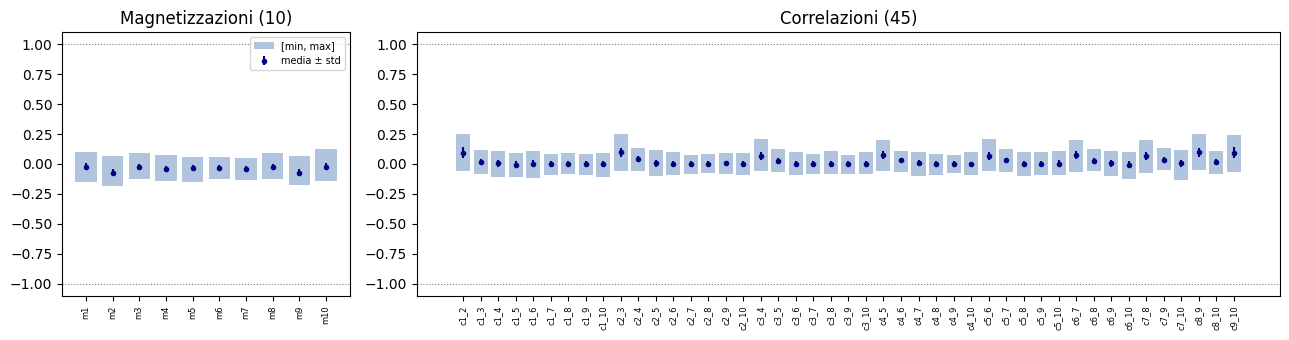

In [9]:
# =============================================================================
# Grafico: Distribuzione Min-Max e Media ± Std per Feature
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5), gridspec_kw={"width_ratios": [1, 3]})
x = np.arange(N_FEATURES)

for ax, sl, title in [(axes[0], MAG_SLICE, "Magnetizzazioni (10)"), (axes[1], CORR_SLICE, "Correlazioni (45)")]:
    s = stats.iloc[sl]
    xs = x[sl]
    ax.bar(xs, s["max"] - s["min"], bottom=s["min"], color="lightsteelblue", label="[min, max]")
    ax.errorbar(xs, s["mean"], yerr=s["std"], fmt="o", ms=3, color="navy", label="media ± std")
    ax.set_xticks(xs)
    ax.set_xticklabels(s.index, rotation=90, fontsize=6)
    ax.axhline(1, color="gray", ls=":", lw=0.8)
    ax.axhline(-1, color="gray", ls=":", lw=0.8)
    ax.set_title(title)

axes[0].legend(fontsize=7)
fig.tight_layout()
print("Grafico esportato:", save_figure(fig, "feature_stats", subdir="01_data"))
plt.show()


Grafico esportato: /content/drive/MyDrive/DL-Quantum/figures/01_data/value_distributions.jpeg


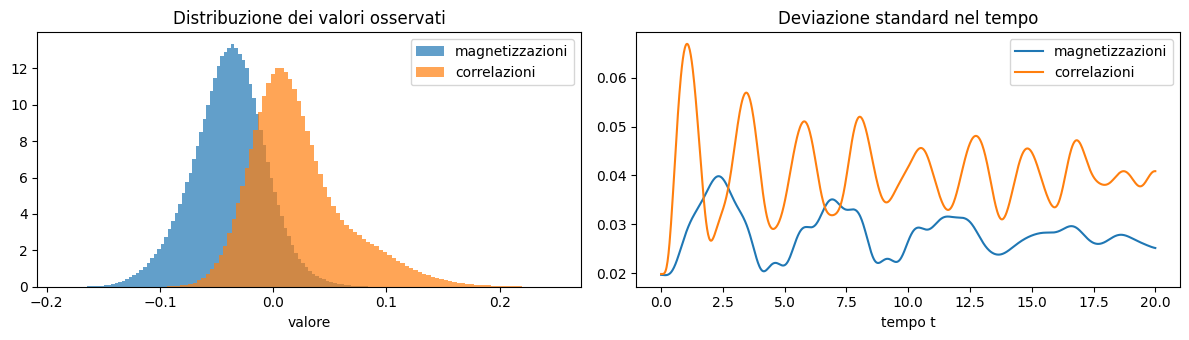

In [10]:
# =============================================================================
# Grafico: Istogrammi di Valore e Dinamica Temporale della Varianza
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))

# Istogramma densità di probabilità dei valori osservati
axes[0].hist(data[..., MAG_SLICE].ravel(), bins=100, alpha=0.7, density=True, label="magnetizzazioni")
axes[0].hist(data[..., CORR_SLICE].ravel(), bins=100, alpha=0.7, density=True, label="correlazioni")
axes[0].set_title("Distribuzione dei valori osservati")
axes[0].set_xlabel("valore")
axes[0].legend()

# Evoluzione della deviazione standard nel tempo
tt = np.arange(N_POINTS) * DT
axes[1].plot(tt, data[..., MAG_SLICE].std(axis=(0, 2)), label="magnetizzazioni")
axes[1].plot(tt, data[..., CORR_SLICE].std(axis=(0, 2)), label="correlazioni")
axes[1].set_xlabel("tempo t")
axes[1].set_title("Deviazione standard nel tempo")
axes[1].legend()

fig.tight_layout()
print("Grafico esportato:", save_figure(fig, "value_distributions", subdir="01_data"))
plt.show()


## 5. Sanity Check Visivo sulle Serie Temporali

Prima di procedere con la modellazione sequenziale, visualizziamo alcune traiettorie campione per ispezionare la propagazione delle magnetizzazioni, il decadimento delle correlazioni con la distanza e la scala delle finestre di input ($T_{in}=10, 20$) rispetto all'orizzonte futuro ($T_{out}=40$).

Grafico esportato: /content/drive/MyDrive/DL-Quantum/figures/01_data/example_trajectories.jpeg


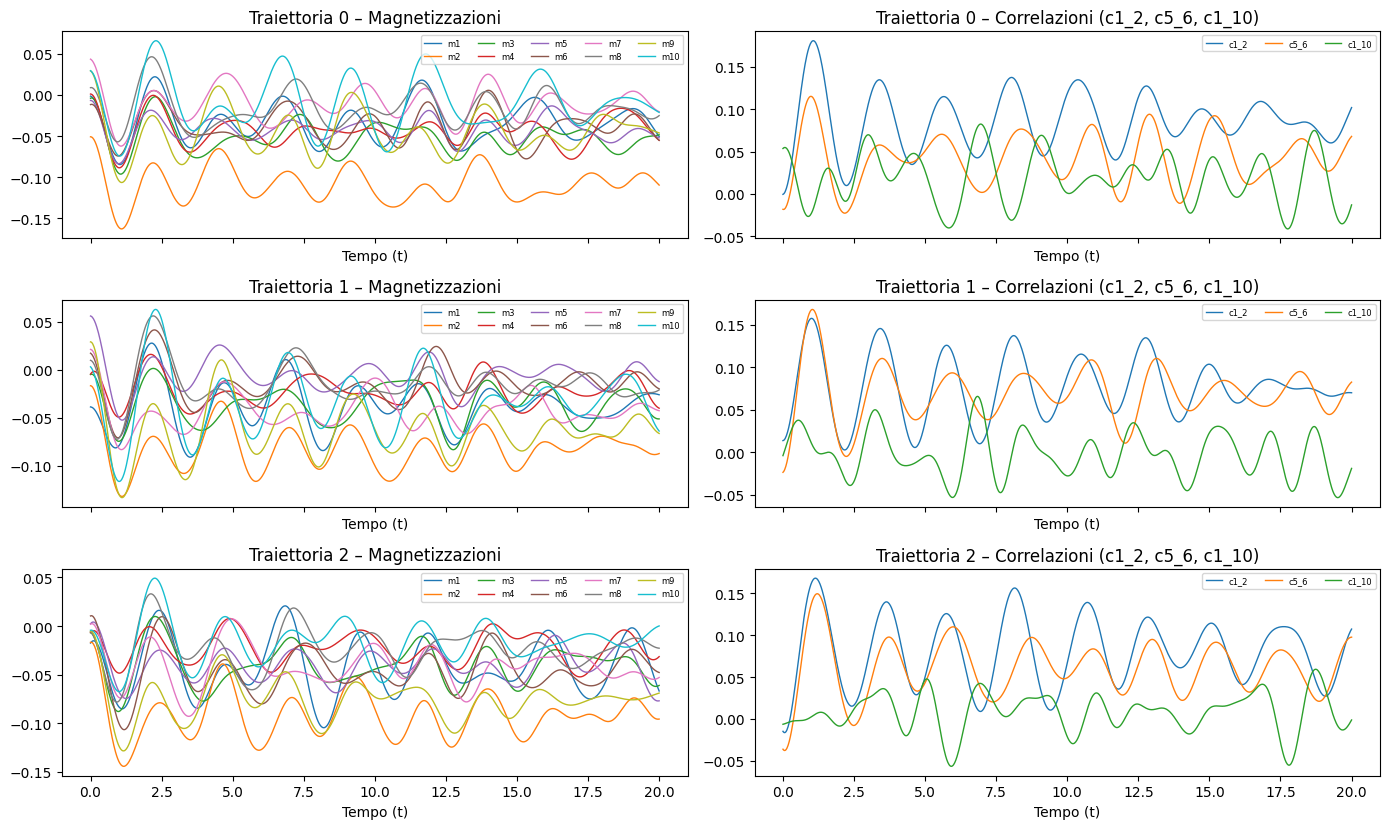

In [11]:
# =============================================================================
# 5. Visualizzazione Traiettorie Campione
# =============================================================================
example_traj = [0, 1, 2]
corr_examples = [NAMES.index(n) for n in ("c1_2", "c5_6", "c1_10")]

fig, axes = plt.subplots(len(example_traj), 2, figsize=(14, 2.8 * len(example_traj)), sharex=True)
for r, tid in enumerate(example_traj):
    plot_trajectory(data[tid], list(range(N_QUBITS)), ax=axes[r, 0],
                    title=f"Traiettoria {tid} – Magnetizzazioni")
    plot_trajectory(data[tid], corr_examples, ax=axes[r, 1],
                    title=f"Traiettoria {tid} – Correlazioni (c1_2, c5_6, c1_10)")
    for ax in axes[r]:
        ax.legend(ncol=5, fontsize=6, loc="upper right")

fig.tight_layout()
print("Grafico esportato:", save_figure(fig, "example_trajectories", subdir="01_data"))
plt.show()


Grafico esportato: /content/drive/MyDrive/DL-Quantum/figures/01_data/zoom_first_steps.jpeg


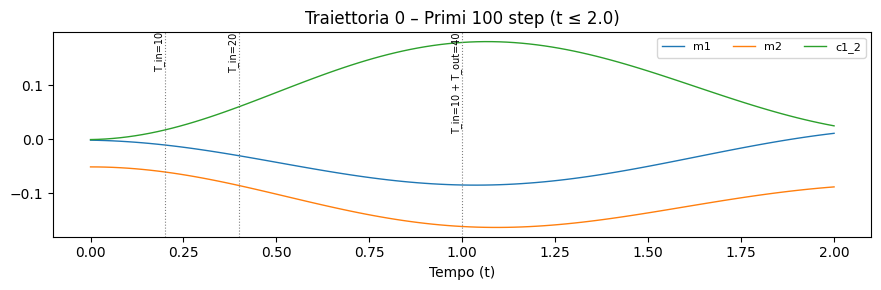

In [12]:
# =============================================================================
# Zoom sui primi 100 step temporali (t <= 2.0) e confronto con orizzonte T_out
# =============================================================================
tid = example_traj[0]
fig, ax = plt.subplots(figsize=(9, 3))
plot_trajectory(data[tid, :101], [0, 1, NAMES.index("c1_2")], ax=ax,
                title=f"Traiettoria {tid} – Primi 100 step (t ≤ 2.0)")

# Linee guida per finestre di input e orizzonte di predizione
for k, lab in [(10, "T_in=10"), (20, "T_in=20"), (50, "T_in=10 + T_out=40")]:
    ax.axvline(k * DT, color="gray", ls=":", lw=0.8)
    ax.text(k * DT, ax.get_ylim()[1], lab, fontsize=7, rotation=90, va="top", ha="right")

fig.tight_layout()
print("Grafico esportato:", save_figure(fig, "zoom_first_steps", subdir="01_data"))
plt.show()


## 6. Split Train / Validation / Test per Traiettoria

**Perché dividiamo per traiettoria e NON per riga:** righe consecutive appartengono alla stessa simulazione fisica; uno split per riga causerebbe grave **data leakage temporale**.
Partizioniamo quindi le 400 traiettorie in **280 Train (70%) / 60 Val (15%) / 60 Test (15%)** e salviamo gli indici in `results/split_indices.npz`.

In [13]:
# =============================================================================
# 6. Partizionamento Anti-Leakage per Traiettoria (280 / 60 / 60)
# =============================================================================
split_path = PATHS["results"] / "split_indices.npz"
new_split = make_split(n_traj=N_TRAJ, n_train=CFG["n_train"], n_val=CFG["n_val"],
                       n_test=CFG["n_test"], seed=CFG["split_seed"])

if split_path.exists():
    split = load_split(split_path)
    same = all(np.array_equal(split[k], new_split[k]) for k in new_split)
    print(f"Split caricato da: {split_path} | Identico allo split teorico (seed=42): {same}")
    assert same, "Discrepanza con lo split salvato!"
else:
    split = new_split
    print("Nuovo split generato e salvato in:", save_split(split, split_path))

# Dimensioni e primi indici di ciascuna partizione
for k, v in split.items():
    print(f"{k.capitalize():10s}: {len(v):3d} traiettorie ({len(v)/N_TRAJ*100:.1f}%) | Primi indici: {v[:6]}")

# Verifiche formali di completezza e disgiunzione
all_idx = np.concatenate([split["train"], split["val"], split["test"]])
assert len(np.unique(all_idx)) == N_TRAJ == len(all_idx), "Lo split non costituisce una partizione esatta!"
assert not (set(split["train"]) & set(split["val"]) or set(split["train"]) & set(split["test"])
            or set(split["val"]) & set(split["test"])), "Rilevato data leakage tra gli insiemi!"
print("Verifica di disgiunzione e completezza partizioni: superata ✔")


Split caricato da: /content/drive/MyDrive/DL-Quantum/results/split_indices.npz | Identico allo split teorico (seed=42): True
Train     : 280 traiettorie (70.0%) | Primi indici: [0 2 3 4 7 8]
Val       :  60 traiettorie (15.0%) | Primi indici: [ 1  5 10 13 17 21]
Test      :  60 traiettorie (15.0%) | Primi indici: [ 6 14 15 16 22 23]
Verifica di disgiunzione e completezza partizioni: superata ✔


In [14]:
# =============================================================================
# Controllo di Omogeneità Distributiva tra Train, Validation e Test
# =============================================================================
rows = []
for k, idx in split.items():
    d = data[idx]
    rows.append({
        "Partizione": k.capitalize(),
        "Media Mag": d[..., MAG_SLICE].mean(),
        "Std Mag": d[..., MAG_SLICE].std(),
        "Media Corr": d[..., CORR_SLICE].mean(),
        "Std Corr": d[..., CORR_SLICE].std()
    })
display(pd.DataFrame(rows).set_index("Partizione").round(4))


,Media Mag,Std Mag,Media Corr,Std Corr
Partizione,,,,
Train,-0.0396,0.0323,0.0216,0.0422
Val,-0.0376,0.0323,0.0215,0.0424
Test,-0.0404,0.0320,0.0220,0.0423


## 7. Normalizzazione: Perché Usiamo i Dati Grezzi (`none` + `tanh`) invece dello Z-Score

Scegliamo deliberatamente di **non applicare lo Z-score** per tre motivi:
1. **Scala comune nativa**: tutte le 55 osservabili di Pauli condividono già lo stesso bound fisico assoluto $[-1, 1]$, dove $0$ indica assenza di polarizzazione/correlazione.
2. **Nessuna amplificazione del rumore**: standardizzare a varianza unitaria correlazioni lontane quasi piatte ($\sigma \approx 0.04$) gonfierebbe il rumore di fondo e distorcerebbe i prodotti scalari nelle mappe di attenzione dei Transformer ($M_3, M_4$).
3. **Stabilità con `tanh`**: mantenere il target in $[-1, 1]$ consente di usare `tanh` in uscita, evitando divergenze nella generazione *free-running* ($M_2, M_4$).

Verifichiamo empiricamente questa scelta su 3 seed (42, 43, 44) con una LSTM di test, confrontando `none` + `tanh` contro `zscore` + uscita lineare sulla scala reale.

In [15]:
# =============================================================================
# 7. Generazione Finestre di Test e Parametri Z-Score (Solo Train)
# =============================================================================
from src.windowing import make_windows
from src.metrics import evaluate
from src.stats import summarize

NORM_N_TRAIN = 100      # Traiettorie di train utilizzate nel confronto proxy
NORM_EPOCHS = 15
NORM_SEEDS = [42, 43, 44]
T_IN, T_OUT, STRIDE = CFG["windows"]["short"], CFG["t_out"], CFG["stride"]

# Creazione delle finestre temporali
sub_tr = split["train"][:NORM_N_TRAIN]
X_tr, Y_tr, _ = make_windows(data, sub_tr, T_IN, T_OUT, STRIDE)
X_va, Y_va, _ = make_windows(data, split["val"], T_IN, T_OUT, STRIDE)
print(f"Finestre temporali create: Train={X_tr.shape[0]} | Validation={X_va.shape[0]}")

# Calcolo parametri z-score RIGOROSAMENTE sul solo train set per evitare leakage
flat_tr = data[split["train"]].reshape(-1, N_FEATURES)
MU = flat_tr.mean(axis=0).astype(np.float32)
SD = flat_tr.std(axis=0).astype(np.float32)
SD = np.where(SD < 1e-8, 1.0, SD).astype(np.float32)
del flat_tr
print("Parametri z-score (media e deviazione standard) calcolati sul solo train set ✔")


Finestre temporali create: Train=9600 | Validation=5760
Parametri z-score (media e deviazione standard) calcolati sul solo train set ✔


In [16]:
# =============================================================================
# Addestramento Proxy: Confronto none (tanh) vs zscore (lineare)
# =============================================================================
def build_direct_lstm(t_in, t_out, n_feat, units=64, out_act="tanh"):
    inp = tf.keras.Input(shape=(t_in, n_feat))
    h = tf.keras.layers.LSTM(units)(inp)
    out = tf.keras.layers.Dense(t_out * n_feat, activation=out_act)(h)
    out = tf.keras.layers.Reshape((t_out, n_feat))(out)
    return tf.keras.Model(inp, out, name=f"lstm_direct_{out_act}")


# Definizione trasformazioni diretta e inversa
NORM_VARIANTS = {
    "none":   dict(fwd=lambda a: a,               inv=lambda a: a,           act="tanh"),
    "zscore": dict(fwd=lambda a: (a - MU) / SD,   inv=lambda a: a * SD + MU, act="linear"),
}

norm_rows, norm_hist = [], {}
if tf is None:
    print("TensorFlow non presente: confronto saltato (eseguire su GPU Colab).")
else:
    for name, v in NORM_VARIANTS.items():
        for seed in NORM_SEEDS:
            set_seeds(seed)
            model = build_direct_lstm(T_IN, T_OUT, N_FEATURES, out_act=v["act"])
            model.compile(optimizer=tf.keras.optimizers.Adam(CFG["lr"]), loss="mse")
            t0 = time.time()
            h = model.fit(
                v["fwd"](X_tr), v["fwd"](Y_tr),
                validation_data=(v["fwd"](X_va), v["fwd"](Y_va)),
                epochs=NORM_EPOCHS, batch_size=CFG["batch_size"], shuffle=True, verbose=0
            )
            # Calcolo predizioni e riporto in scala fisica originale prima della metrica
            pred = v["inv"](model.predict(v["fwd"](X_va), batch_size=256, verbose=0))
            m = evaluate(Y_va, pred)
            train_time = time.time() - t0
            norm_rows.append({"normalization": name, "seed": seed, **m, "train_time_s": train_time})
            norm_hist[(name, seed)] = h.history
            print(f"{name:6s} | Seed {seed}: Val MSE = {m['mse']:.5f} (mag: {m['mse_mag']:.5f}, corr: {m['mse_corr']:.5f}) | Tempo: {train_time:.1f}s")
            tf.keras.backend.clear_session()


none   | Seed 42: Val MSE = 0.00022 (mag: 0.00011, corr: 0.00024) | Tempo: 17.6s
none   | Seed 43: Val MSE = 0.00022 (mag: 0.00011, corr: 0.00024) | Tempo: 16.6s
none   | Seed 44: Val MSE = 0.00022 (mag: 0.00011, corr: 0.00024) | Tempo: 15.7s
zscore | Seed 42: Val MSE = 0.00023 (mag: 0.00013, corr: 0.00026) | Tempo: 15.7s
zscore | Seed 43: Val MSE = 0.00023 (mag: 0.00013, corr: 0.00025) | Tempo: 15.8s
zscore | Seed 44: Val MSE = 0.00023 (mag: 0.00013, corr: 0.00026) | Tempo: 16.0s


,MSE,MSE_MAG,MSE_CORR,MAE
Normalizzazione,,,,
none,0.00022 ± 0.00000,0.00011 ± 0.00000,0.00024 ± 0.00000,0.01105 ± 0.00002
zscore,0.00023 ± 0.00000,0.00013 ± 0.00000,0.00025 ± 0.00000,0.01135 ± 0.00011


Grafico esportato: /content/drive/MyDrive/DL-Quantum/figures/01_data/normalization_loss_curves.jpeg


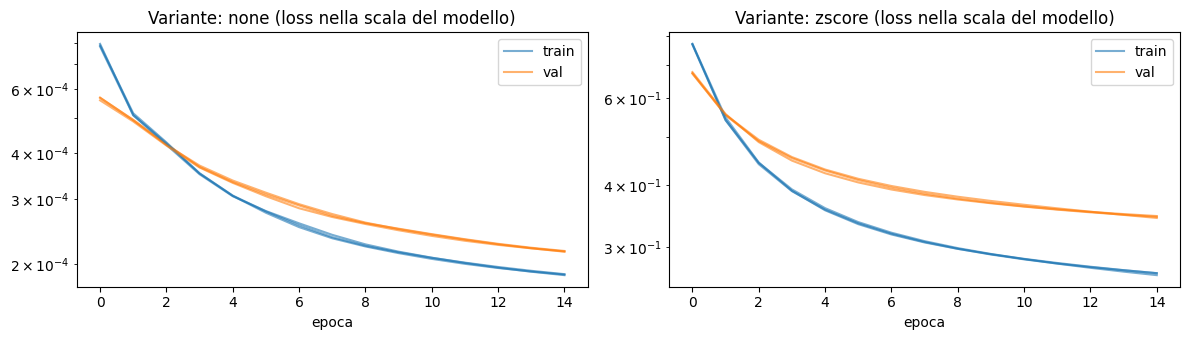

Migliore in media: 'none' | Intervalli di confidenza 95% disgiunti: True
→ Scelta confermata a favore di 'none': output tanh vincolato naturalmente al range quantistico [-1, 1].


In [17]:
# =============================================================================
# Risultati del Confronto e Test di Significatività Statistica
# =============================================================================
if norm_rows:
    norm_df = pd.DataFrame(norm_rows)
    norm_df.to_csv(PATHS["results"] / "normalization_comparison.csv", index=False)

    # Tabella riassuntiva media ± intervallo di confidenza al 95% (t di Student)
    summary = []
    for name, g in norm_df.groupby("normalization"):
        row = {"Normalizzazione": name}
        for m in ["mse", "mse_mag", "mse_corr", "mae"]:
            s = summarize(g[m])
            row[m.upper()] = f"{s['mean']:.5f} ± {s['ci_half']:.5f}"
        summary.append(row)
    display(pd.DataFrame(summary).set_index("Normalizzazione"))

    # Curve di loss (train in blu, validation in arancione)
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
    for ax, name in zip(axes, NORM_VARIANTS):
        for seed in NORM_SEEDS:
            hh = norm_hist[(name, seed)]
            ax.plot(hh["loss"], color="C0", alpha=0.6, label="train" if seed == NORM_SEEDS[0] else None)
            ax.plot(hh["val_loss"], color="C1", alpha=0.6, label="val" if seed == NORM_SEEDS[0] else None)
        ax.set_title(f"Variante: {name} (loss nella scala del modello)")
        ax.set_xlabel("epoca")
        ax.set_yscale("log")
        ax.legend()
    fig.tight_layout()
    print("Grafico esportato:", save_figure(fig, "normalization_loss_curves", subdir="01_data"))
    plt.show()

    # Verifica sovrapposizione degli intervalli di confidenza
    means = norm_df.groupby("normalization")["mse"].mean()
    ci = {n: summarize(g["mse"]) for n, g in norm_df.groupby("normalization")}
    overlap = not (ci["none"]["ci_high"] < ci["zscore"]["ci_low"] or ci["zscore"]["ci_high"] < ci["none"]["ci_low"])
    best = means.idxmin()
    print(f"Migliore in media: '{best}' | Intervalli di confidenza 95% disgiunti: {not overlap}")
    if overlap:
        print("→ Differenza non significativa: si preferisce 'none' (più semplice, output tanh vincolato al range fisico).")
    else:
        print(f"→ Scelta confermata a favore di '{best}': output tanh vincolato naturalmente al range quantistico [-1, 1].")


## 8. Checklist di Convalida Finale

Controllo automatico di tutte le proprietà strutturali e di integrità prima di passare al windowing.

In [18]:
# =============================================================================
# 8. Checklist di Validazione Finale
# =============================================================================
checklist = {
    "shape coerente (400400, 56)": report["shape_ok"],
    "assenza di NaN": report["no_nan"],
    "400 traiettorie con t=0": report["n_traj_ok"],
    "griglia temporale uniforme (dt=0.02)": report["time_grid_ok"],
    "valori nel range fisico [-1, 1]": report["in_unit_range"],
    "vincoli quantistici rispettati (P >= 0)": n_viol == 0,
    "reshape strutturato (400, 1001, 55)": data.shape == (N_TRAJ, N_POINTS, N_FEATURES),
    "cache binaria .npy salvata": cache_path.exists(),
    "split per traiettoria salvato e disgiunto": split_path.exists(),
    "confronto normalizzazione eseguito": bool(norm_rows),
}

for k, v in checklist.items():
    print(f"{'✔' if v else '✘'} {k}")

all_passed = all(checklist.values())
print("\n" + ("=" * 50))
print("VALIDAZIONE DATI:", "COMPLETATA CON SUCCESSO ✔" if all_passed else "DA COMPLETARE / ANOMALIE RILEVATE ✘")
print("=" * 50)


✔ shape coerente (400400, 56)
✔ assenza di NaN
✔ 400 traiettorie con t=0
✔ griglia temporale uniforme (dt=0.02)
✔ valori nel range fisico [-1, 1]
✔ vincoli quantistici rispettati (P >= 0)
✔ reshape strutturato (400, 1001, 55)
✔ cache binaria .npy salvata
✔ split per traiettoria salvato e disgiunto
✔ confronto normalizzazione eseguito

VALIDAZIONE DATI: COMPLETATA CON SUCCESSO ✔


## 9. Conclusioni e Prossimo Passo

* **Artefatti pronti**: tensore verificato in `data/cache/trajectories.npy` e split congelato in `results/split_indices.npz`.
* **Normalizzazione**: confermata la scelta dei dati grezzi in $[-1, 1]$ con attivazione finale `tanh` ($\text{Val MSE } \mathbf{0.000216}$ vs $0.000232$ dello Z-score).

👉 **Prossimo passo (`02_windowing.ipynb`)**: definizione della funzione di finestratura condivisa (`short` e `long`), della griglia allineata per la **Sfida 1** e del sottocampionamento $\times 2$ per la **Sfida 2**.

## 10. Sincronizzazione e Push su GitHub

Rilevamento automatico del branch (`dev-ernesto` o `dev-riccardo`) e push degli artefatti e dei grafici aggiornati.

In [19]:
# =============================================================================
# Sincronizzazione dei Risultati e Push su GitHub (Multi-Utente)
# =============================================================================
import os
from pathlib import Path

target_repo = Path("/content/drive/MyDrive/DL-Quantum") if Path("/content/drive/MyDrive/DL-Quantum").exists() else REPO_PATH

print(f"--- SINCRONIZZAZIONE SUL BRANCH: {CURRENT_BRANCH} (Autore: {AUTHOR_NAME}) ---")

# 1. Configura l'identità Git dell'autore attivo
!git -C "{target_repo}" config user.name "{AUTHOR_NAME}"
!git -C "{target_repo}" config user.email "{AUTHOR_EMAIL}"

# 2. Allineamento preventivo con eventuali nuovi commit remoti (evita non-fast-forward)
!git -C "{target_repo}" fetch origin
!git -C "{target_repo}" pull --rebase --autostash origin {CURRENT_BRANCH}

# 3. Aggiunge i risultati numerici, figure, notebook e codice al tracking Git
!git -C "{target_repo}" add results/ figures/ notebooks/ src/
commit_msg = f"feat: aggiornamento risultati da Colab [{CURRENT_BRANCH}] di {AUTHOR_NAME}"
!git -C "{target_repo}" commit -m "{commit_msg}"
!git -C "{target_repo}" status -s

# 4. Push su GitHub con il token personale rilevato
if GIT_TOKEN:
    print(f"\nPush automatico in corso sul branch '{CURRENT_BRANCH}' con token di {AUTHOR_NAME}...")
    push_out = !git -C "{target_repo}" push https://{GIT_TOKEN}@github.com/Riccardo-27/DL-Quantum.git {CURRENT_BRANCH}
    print("\n".join(push_out))

    # Verifica esito del comando di push
    push_err = any("rejected" in l.lower() or "error:" in l.lower() or "fatal:" in l.lower() for l in push_out)
    if push_err:
        print(f"\n[ATTENZIONE] Il push è stato respinto. Risolvi eventuali divergenze con '!git -C \"{target_repo}\" pull --rebase --autostash origin {CURRENT_BRANCH}' e riprova.")
    else:
        print(f"\n✔ Sincronizzazione completata con successo su '{CURRENT_BRANCH}'!")
else:
    if IN_COLAB:
        print("\n[ATTENZIONE] Nessun token rilevato per il push automatico su Colab.")
        print("  - Se sei Ernesto: crea il segreto 'GIT_E_TOKEN' nell'icona 🔑 a sinistra.")
        print("  - Se sei Riccardo: crea il segreto 'GIT_R_TOKEN' nell'icona 🔑 a sinistra.")
    else:
        print(f"\nAmbiente locale: per il push esegui 'git push origin {CURRENT_BRANCH}' da terminale.")



--- SINCRONIZZAZIONE SUL BRANCH: dev-ernesto (Autore: Ernesto Gligora) ---
From https://github.com/Riccardo-27/DL-Quantum
 * branch            dev-ernesto -> FETCH_HEAD
Already up to date.
[dev-ernesto 36085ea] feat: aggiornamento risultati da Colab [dev-ernesto] di Ernesto Gligora
 3 files changed, 6 insertions(+), 6 deletions(-)

Push automatico in corso sul branch 'dev-ernesto' con token di Ernesto Gligora...
Enumerating objects: 15, done.
Counting objects:   6% (1/15)
Counting objects:  13% (2/15)
Counting objects:  20% (3/15)
Counting objects:  26% (4/15)
Counting objects:  33% (5/15)
Counting objects:  40% (6/15)
Counting objects:  46% (7/15)
Counting objects:  53% (8/15)
Counting objects:  60% (9/15)
Counting objects:  66% (10/15)
Counting objects:  73% (11/15)
Counting objects:  80% (12/15)
Counting objects:  86% (13/15)
Counting objects:  93% (14/15)
Counting objects: 100% (15/15)
Counting objects: 100% (15/15), done.
Delta compression using up to 2 threads
Compressing objects